# German Credit Data: Collection, Cleaning, and Exploration

**Name:** Minh Le, Sebastian Capkovi, Shreyas More, Elkana Munganga
**Course:** MSCS-634 – Advanced Big Data and Data Mining
**Project:** Deliverable 1 – Data Collection, Cleaning, and Exploration
**Semester:** Fall 2026

## Dataset Description

This project uses the German Credit Data dataset from Kaggle, containing 1,000 records and nine meaningful attributes related to credit applicants and their loans.

The dataset includes age, sex, job category, housing status, savings accounts, checking accounts, credit amount, loan duration, and loan purpose.

I selected this dataset because it provides an opportunity to explore financial and demographic patterns, examine data quality issues, and prepare the data for future regression, classification, and clustering models.

**Dataset Source:** https://www.kaggle.com/datasets/varunchawla30/german-credit-data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
# Load the German Credit dataset
df = pd.read_csv("german_credit_data.csv")

# Remove the unnecessary index column
df = df.drop(columns=["Unnamed: 0"])

# Display the first five records
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (1000, 9)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


In [4]:
# Examine column names and data types
print("Dataset Information:")
df.info()

# Display descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               1000 non-null   int64
 1   Sex               1000 non-null   str  
 2   Job               1000 non-null   int64
 3   Housing           1000 non-null   str  
 4   Saving accounts   817 non-null    str  
 5   Checking account  606 non-null    str  
 6   Credit amount     1000 non-null   int64
 7   Duration          1000 non-null   int64
 8   Purpose           1000 non-null   str  
dtypes: int64(4), str(5)
memory usage: 70.4 KB

Descriptive Statistics:


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
count,1000.000000,1000,1000.000000,1000,817,606,1000.000000,1000.000000,1000
unique,NaN,2,NaN,3,4,3,NaN,NaN,8
top,NaN,male,NaN,own,little,little,NaN,NaN,car
freq,NaN,690,NaN,713,603,274,NaN,NaN,337
mean,35.546000,NaN,1.904000,NaN,NaN,NaN,3271.258000,20.903000,NaN
std,11.375469,NaN,0.653614,NaN,NaN,NaN,2822.736876,12.058814,NaN
min,19.000000,NaN,0.000000,NaN,NaN,NaN,250.000000,4.000000,NaN
25%,27.000000,NaN,2.000000,NaN,NaN,NaN,1365.500000,12.000000,NaN
50%,33.000000,NaN,2.000000,NaN,NaN,NaN,2319.500000,18.000000,NaN
75%,42.000000,NaN,2.000000,NaN,NaN,NaN,3972.250000,24.000000,NaN


In [5]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate missing value percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentages:")
print(missing_percentage.round(2))

Missing Values:
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

Missing Value Percentages:
Age                  0.0
Sex                  0.0
Job                  0.0
Housing              0.0
Saving accounts     18.3
Checking account    39.4
Credit amount        0.0
Duration             0.0
Purpose              0.0
dtype: float64


In [6]:
# Create a cleaned copy of the dataset
df_clean = df.copy()

# Fill missing categorical values
df_clean["Saving accounts"] = df_clean["Saving accounts"].fillna("Unknown")
df_clean["Checking account"] = df_clean["Checking account"].fillna("Unknown")

# Verify missing values have been handled
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

Missing Values After Cleaning:
Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
dtype: int64


In [7]:
# Count duplicate records
duplicates = df_clean.duplicated().sum()

print("Duplicate Records:", duplicates)

# Remove exact duplicates if any exist
df_clean = df_clean.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df_clean.shape)

Duplicate Records: 0
Dataset Shape After Removing Duplicates: (1000, 9)


In [8]:
# Inspect unique values in categorical columns
categorical_columns = df_clean.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts())


Sex:
Sex
male      690
female    310
Name: count, dtype: int64

Housing:
Housing
own     713
rent    179
free    108
Name: count, dtype: int64

Saving accounts:
Saving accounts
little        603
Unknown       183
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64

Checking account:
Checking account
Unknown     394
little      274
moderate    269
rich         63
Name: count, dtype: int64

Purpose:
Purpose
car                    337
radio/TV               280
furniture/equipment    181
business                97
education               59
repairs                 22
domestic appliances     12
vacation/others         12
Name: count, dtype: int64


/var/folders/4v/vbdgw59d1zl9vsy40nppxtcw0000gn/T/ipykernel_6530/1292799154.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(


In [9]:
# Remove leading and trailing spaces from text columns
for column in categorical_columns:
    df_clean[column] = df_clean[column].str.strip()

# Check for invalid numerical values
print("Invalid Ages:", (df_clean["Age"] <= 0).sum())
print("Invalid Credit Amounts:", (df_clean["Credit amount"] <= 0).sum())
print("Invalid Loan Durations:", (df_clean["Duration"] <= 0).sum())

# Check data types
print("\nCleaned Dataset Information:")
df_clean.info()

Invalid Ages: 0
Invalid Credit Amounts: 0
Invalid Loan Durations: 0

Cleaned Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               1000 non-null   int64
 1   Sex               1000 non-null   str  
 2   Job               1000 non-null   int64
 3   Housing           1000 non-null   str  
 4   Saving accounts   1000 non-null   str  
 5   Checking account  1000 non-null   str  
 6   Credit amount     1000 non-null   int64
 7   Duration          1000 non-null   int64
 8   Purpose           1000 non-null   str  
dtypes: int64(4), str(5)
memory usage: 70.4 KB


In [10]:
# Save cleaned data for future analysis
df_clean.to_csv("german_credit_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final Dataset Shape:", df_clean.shape)

Cleaned dataset saved successfully!
Final Dataset Shape: (1000, 9)


## Step 2: Data Cleaning

We examined the German Credit dataset for missing values, duplicate records, inconsistent categorical values, and potentially invalid numerical entries.

The Saving accounts and Checking account columns contained missing values. We replaced these with "Unknown" to preserve the original records without making assumptions about customers' financial information.

We checked for duplicate observations and removed exact duplicates where applicable. We also inspected categorical values for inconsistencies and removed unnecessary whitespace.

Finally, we checked age, credit amount, and loan duration for invalid values and saved the cleaned dataset for exploratory analysis and future modeling.

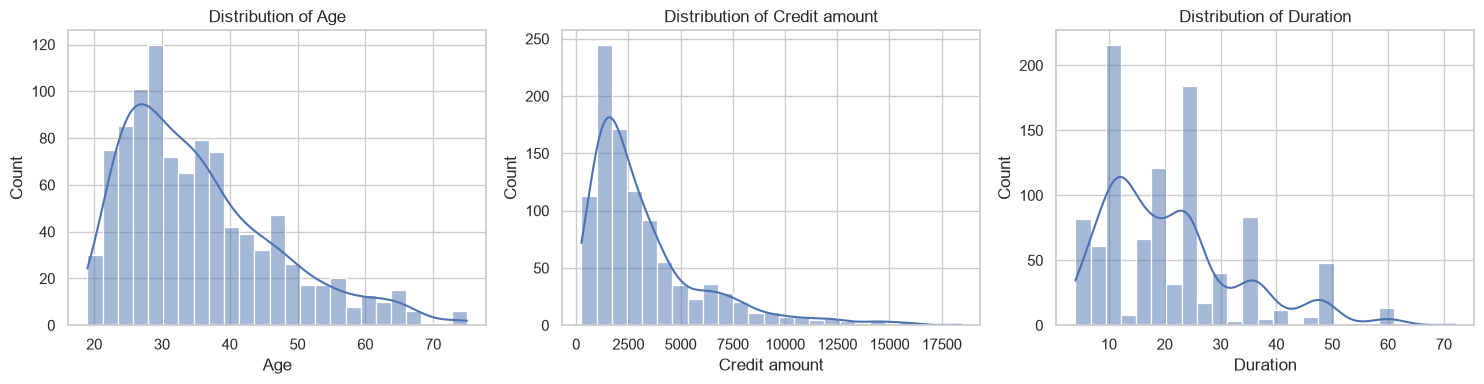

In [12]:
# Visualize distributions of numerical features
numerical_columns = ["Age", "Credit amount", "Duration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numerical_columns):
    sns.histplot(
        df_clean[column],
        bins=25,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

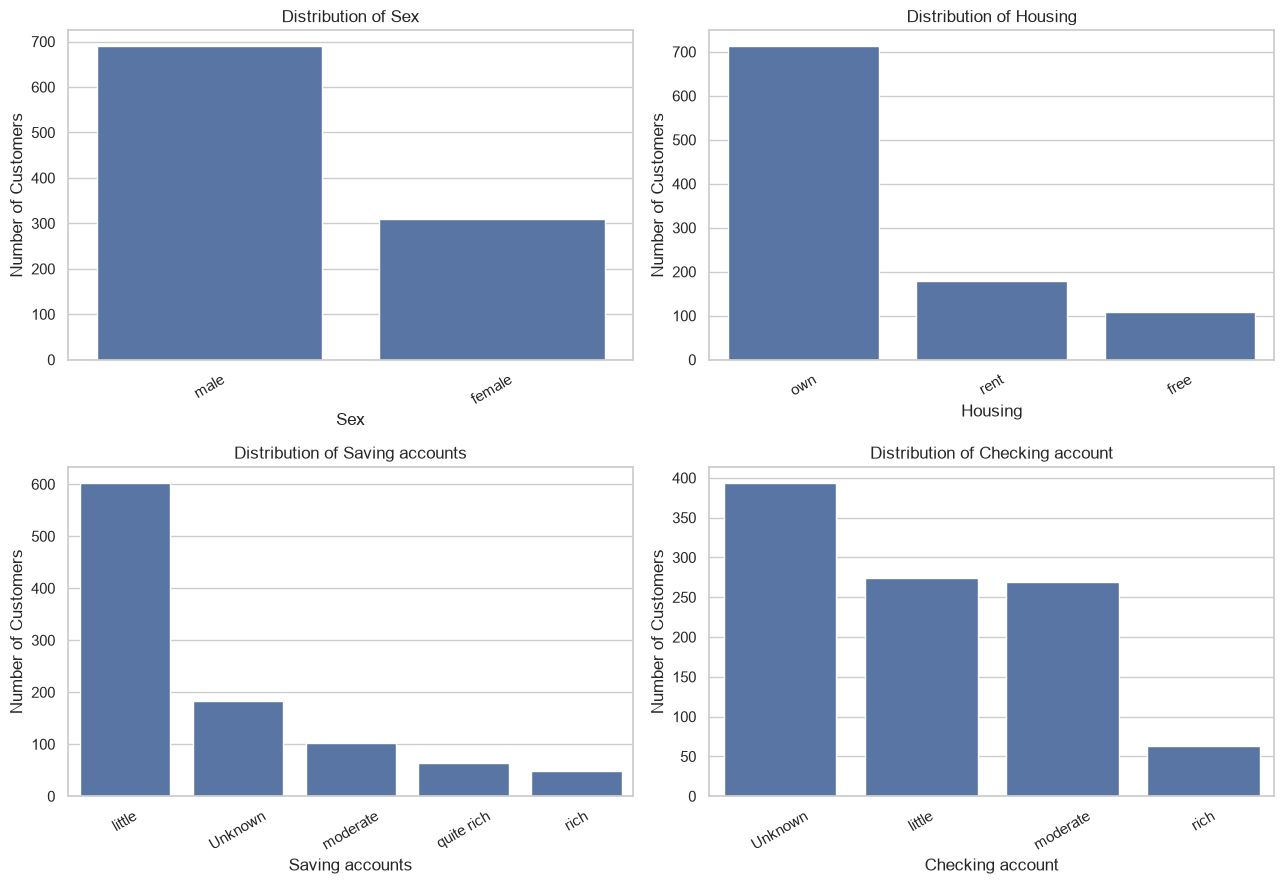

In [13]:
# Examine the distribution of categorical attributes
columns = ["Sex", "Housing", "Saving accounts", "Checking account"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, column in zip(axes.flatten(), columns):
    order = df_clean[column].value_counts().index

    sns.countplot(
        data=df_clean,
        x=column,
        order=order,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

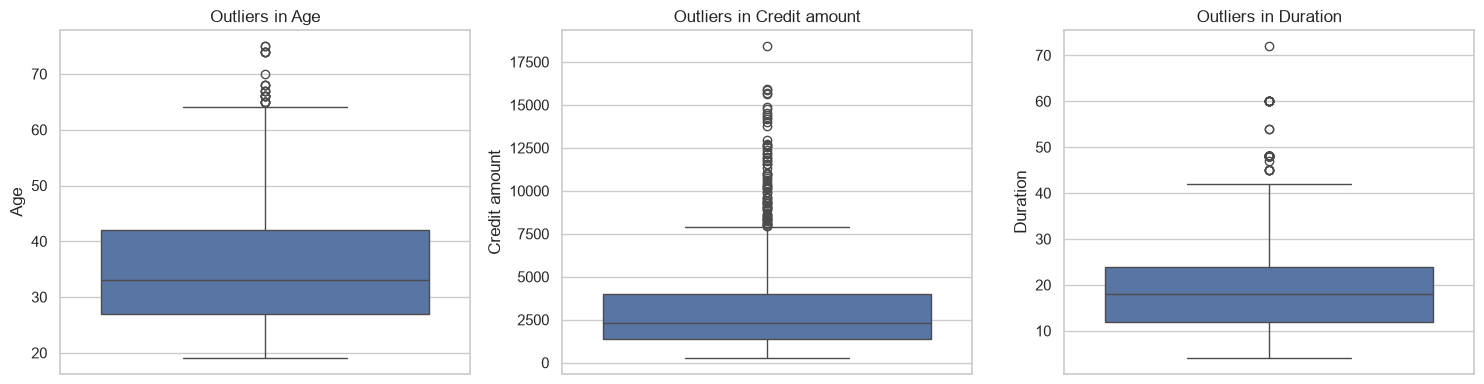

In [14]:
# Identify potential outliers in numerical features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(
        y=df_clean[column],
        ax=ax
    )

    ax.set_title(f"Outliers in {column}")

plt.tight_layout()
plt.show()

In [15]:
# Calculate potential outliers using the IQR method
for column in numerical_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} potential outliers")

Age: 23 potential outliers
Credit amount: 72 potential outliers
Duration: 70 potential outliers


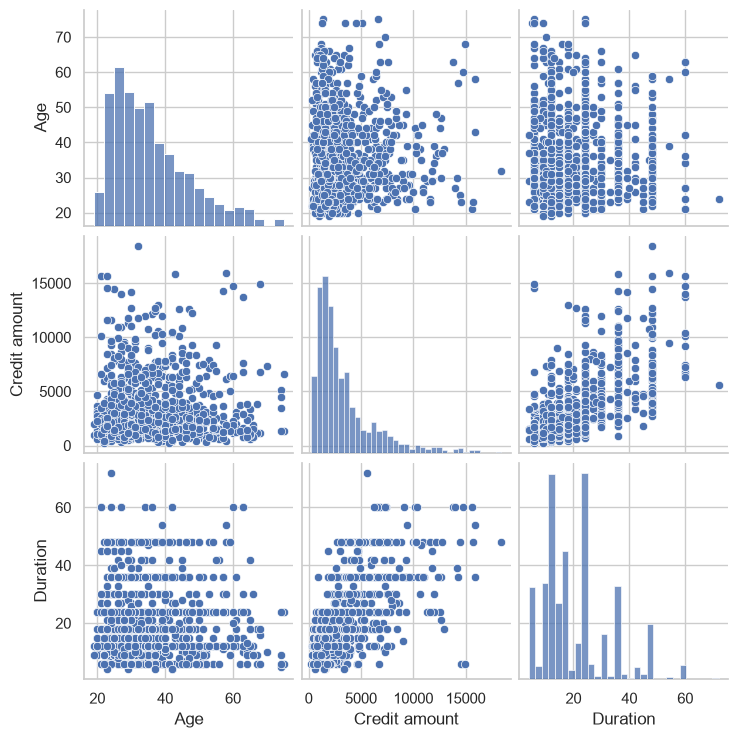

In [16]:
# Examine relationships between numerical features
sns.pairplot(
    df_clean[numerical_columns],
    diag_kind="hist"
)

plt.show()

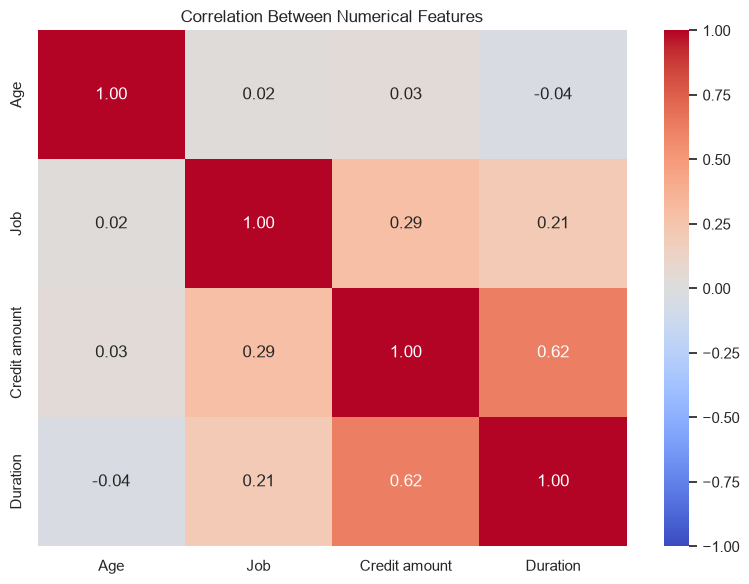

In [17]:
# Calculate correlations between numerical features
correlation_columns = ["Age", "Job", "Credit amount", "Duration"]

correlation_matrix = df_clean[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

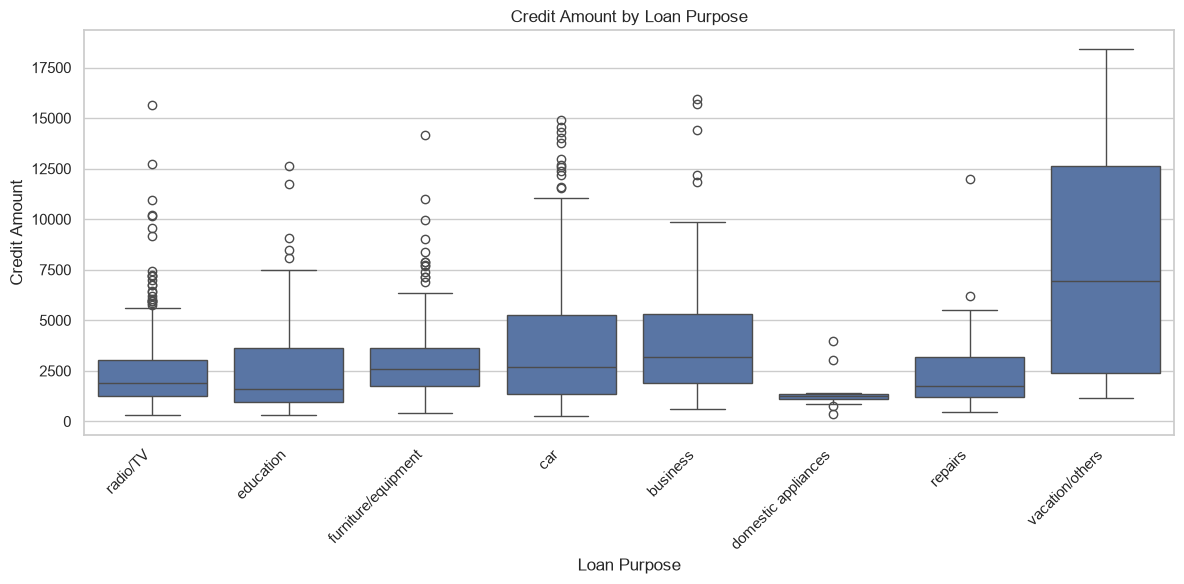

In [18]:
# Compare credit amounts across different loan purposes
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean,
    x="Purpose",
    y="Credit amount"
)

plt.title("Credit Amount by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Credit Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

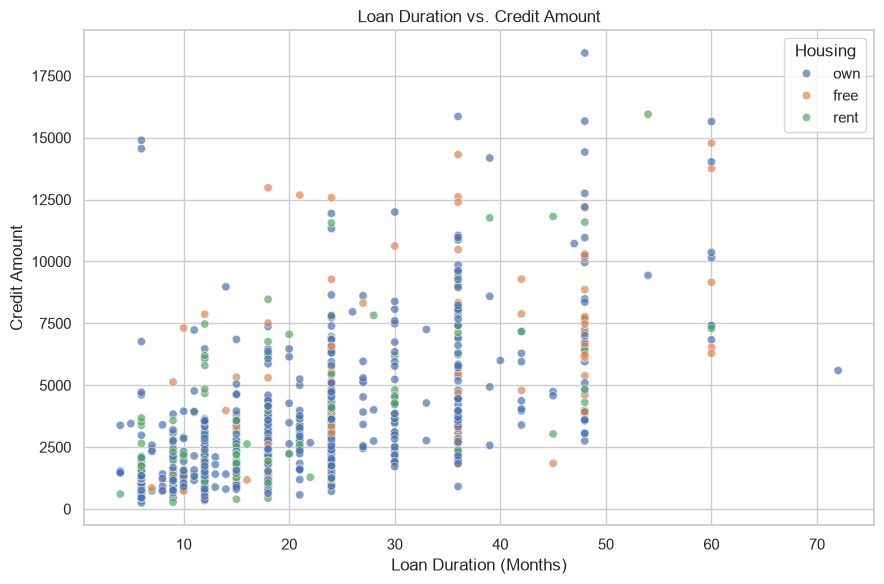

In [19]:
# Examine the relationship between loan duration and credit amount
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clean,
    x="Duration",
    y="Credit amount",
    hue="Housing",
    alpha=0.7
)

plt.title("Loan Duration vs. Credit Amount")
plt.xlabel("Loan Duration (Months)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()

## Step 3: Exploratory Data Analysis

We performed exploratory data analysis using Matplotlib and Seaborn to examine the German Credit dataset.

We used histograms to explore the distributions of age, credit amount, and loan duration. Count plots helped us examine the frequency of categorical attributes, including sex, housing status, savings accounts, and checking accounts.

We used boxplots and the Interquartile Range (IQR) method to identify potential outliers. We retained these observations because unusually high credit amounts or loan durations may represent legitimate financial transactions rather than data errors.

We also examined relationships between numerical features using scatter plots, pair plots, and a correlation heatmap. Finally, we compared credit amounts across loan purposes and explored the relationship between credit amount and loan duration.

These visualizations provide a foundation for identifying useful features and selecting appropriate data preprocessing techniques for future predictive modeling.

In [20]:
# Summarize the key findings from exploratory analysis
print("Total Records:", len(df_clean))
print("Total Attributes:", df_clean.shape[1])
print("Missing Values Remaining:", df_clean.isnull().sum().sum())

print("\nAverage Credit Amount:", round(df_clean["Credit amount"].mean(), 2))
print("Median Credit Amount:", round(df_clean["Credit amount"].median(), 2))
print("Average Loan Duration:", round(df_clean["Duration"].mean(), 2))
print("Average Customer Age:", round(df_clean["Age"].mean(), 2))

print("\nMost Common Loan Purpose:")
print(df_clean["Purpose"].value_counts().head(3))

print("\nCredit Amount and Duration Correlation:")
print(round(df_clean["Credit amount"].corr(df_clean["Duration"]), 4))

Total Records: 1000
Total Attributes: 9
Missing Values Remaining: 0

Average Credit Amount: 3271.26
Median Credit Amount: 2319.5
Average Loan Duration: 20.9
Average Customer Age: 35.55

Most Common Loan Purpose:
Purpose
car                    337
radio/TV               280
furniture/equipment    181
Name: count, dtype: int64

Credit Amount and Duration Correlation:
0.625


## Step 4: EDA Insights and Future Modeling

The exploratory analysis of the German Credit dataset provided insights into customer demographics, loan characteristics, and financial behavior.

The distributions of credit amounts and loan durations helped identify differences in borrowing patterns. The boxplots also revealed potential outliers, particularly among larger credit amounts. We retained these observations because they may represent legitimate financial transactions.

The analysis of categorical variables highlighted differences in housing status, savings accounts, checking accounts, and loan purposes. These attributes may provide useful information for understanding customer segments.

The correlation analysis helped us examine relationships between numerical features, particularly credit amount and loan duration. We will consider these relationships during feature selection and model development.

### Future Modeling Preparation

For Deliverable 2, we plan to predict credit amounts using regression techniques such as Linear Regression and Ridge Regression.

For Deliverable 3, we can apply clustering techniques such as K-Means to identify groups of customers with similar financial characteristics. We can also explore classification by defining a suitable categorical target from the available data and apply association rule mining to identify relationships between customer attributes and loan characteristics.

Before modeling, we will encode categorical variables, scale numerical features where appropriate, and evaluate potential data leakage. We will also consider privacy and fairness when using demographic or financial information.

Overall, the data cleaning and exploration process established a foundation for future predictive modeling and pattern discovery.